# Module Seven Activity

For the module seven activity, you will identify relevant data and write Python code to generate visualizations and interpret insights from the provided data set. Professionals in data-driven fields must not only interpret data but also gather, analyze, and present it in meaningful and actionable ways. This activity allows you to practice these essential skills by working through the complete exploratory data analysis (EDA) process.

<div class="alert alert-block alert-danger">
    <span style="color:black"><b><i>Note:</i></b> there are two parts to this assignment. Part One is the coding activity. Part Two is the written report.</span>
</div>

Once your code is complete, you will download this notebook as an HTML file by clicking **File**, then **Download As**, then **HTML (.html)** from the Jupyter menu bar. Validate that your code, output, and all visualizations (rendered as images using the display() function) are visible in the html file before submission.

<div class="alert alert-block alert-danger">
    <span style="color:black"><b><i>Missing Blocks:</i></b> Ensure that you have clicked <b><mark>Run</mark></b> for all blocks before downloading as an HTML file or the block may be missing from your submission. <b>Images</b> must be called using the <b><i>display()</i></b> function, for example: <b><mark>display(Image(filename="output/{image_name}.png"))</mark></b></span>
</div>

Specifically, you must address the items from the rubric criteria.

### Part One: Python Code
In this part, you will write Python code to analyze the data and generate visualizations that explore trends.

#### Create multiple, distinct visualizations that explore different aspects of the data using Python Libraries. 
Include the following: 
- Code comments explaining each step of your analysis

### Part Two: Report
In this part, you will write a reflection to explain the insights gained from your analysis and visualizations. <i>This part is to be completed in a word document, using the output here to answer the topics.</i>
- Explain the trends, differences, or outliers you observed in the data. 
- Describe any disparities or patterns that may be relevant to the nonprofit’s goals. 
- Write a summary of what the data suggests about transit usage across neighborhoods. 
- Explain how the visualizations support your conclusions. 
- Discuss how your findings could inform the nonprofit’s decision-making or strategy. 
- Describe the importance of data-driven insights in addressing real-world challenges.

<div class="alert alert-block alert-success">
    <span style="color:black"><b><i>To Begin:</i></b> This Python template program has been broken down into segments as a guide for what steps you should do at a minimum to complete this activity. Look for the <b># To Do:</b> comments. These are placeholders for you to provide Python code segments. Fill out all <b># To Do:</b> code segments to complete this program.</span><br/><br/>
    <span style="color:black"><b><i>Once Complete:</i></b> Execute a "Kernel restart and run all" to verify that all your code works as a single unit by clicking <b>Kernel</b>, then <b>Restart & Run All</b> before downloading as html.</span>
</div>

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Hint:</i></b> If you need to install additional packages, see one of the earlier modules on how to configure and call a requirements.txt file.</span>
</div>

## Import the Required Packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import matplotlib.image as mpimg

from IPython.display import Image, display # for image rendering in html output

# Part One: Python Code

<div class="alert alert-block alert-success">
    <span style="color:black"><b><i>Reminder:</i></b> Ensure that you add code comments explaining each step of your analysis.</span>
</div>

## Define the file path for the dataset

In [2]:
data_path = "data/Feb_2025_Complete_Monthly_Ridership.csv"

## Loading the dataset

In [3]:
# Load the February 2025 public transit ridership dataset
# into a pandas DataFrame for analysis.
df = pd.read_csv(data_path)

# Confirm that the dataset loaded successfully.
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)


Dataset loaded successfully!
Number of rows and columns: (2311, 27)


## Create an output folder if it doesn't already exist

In [4]:
output_folder = "output"
os.makedirs(output_folder, exist_ok=True)

## Display Dataset Information

In [5]:
# Display the first five rows to examine the dataset.
print("Dataset Overview:")
print(df.head())

# Display the number of records and columns.
print("\nDataset Dimensions:")
print(df.shape)

# Display the data types for each column.
print("\nData Types:")
print(df.dtypes)


Dataset Overview:
   NTD ID Legacy NTD ID       Agency Mode TOS 3 Mode   
0       1          0001  King County   DR  PT    Bus  \
1       1          0001  King County   DR  TX    Bus   
2       1          0001  King County   FB  DO  Ferry   
3       1          0001  King County   LR  DO   Rail   
4       1          0001  King County   MB  DO    Bus   

  Mode/Type of Service Status  Reporter Type   
0                      Active  Full Reporter  \
1                      Active  Full Reporter   
2                      Active  Full Reporter   
3                    Inactive  Full Reporter   
4                      Active  Full Reporter   

                                   Organization Type  HQ City  ...   
0  City, County or Local Government Unit or Depar...  SEATTLE  ...  \
1  City, County or Local Government Unit or Depar...  SEATTLE  ...   
2  City, County or Local Government Unit or Depar...  SEATTLE  ...   
3  City, County or Local Government Unit or Depar...  SEATTLE  ...   
4  Cit

In [6]:
# Display all column names to identify the information
# available for analyzing transit ridership.
print("Column Names:")
for column in df.columns:
    print(column)

Column Names:
NTD ID
Legacy NTD ID
Agency
Mode
TOS
3 Mode
Mode/Type of Service Status
Reporter Type
Organization Type
HQ City
HQ State
UACE CD
UZA Name
UZA SQ Miles
UZA Population
Service Area Population
Service Area SQ Miles
Last Closed Report Year
Last Closed FY End Month
Last Closed FY End Year
Passenger Miles FY
Unlinked Passenger Trips FY
Avg Trip Length FY
Fares FY
Operating Expenses FY
Avg Cost Per Trip FY
Avg Fares Per Trip FY


In [7]:
# Define the three transit agencies for comparison.
neighborhoods = [
    "King County",
    "City of Longview",
    "Spokane Transit Authority"
]

# Select only exact agency matches and create a copy.
filtered_df = df[
    df["Agency"].astype(str).str.strip().isin(neighborhoods)
].copy()

# Confirm the number of records for each agency.
print("Number of matching records:", len(filtered_df))
print("\nTransit agencies included:")
print(filtered_df["Agency"].value_counts())

Number of matching records: 17

Transit agencies included:
Agency
King County                  9
Spokane Transit Authority    4
City of Longview             4
Name: count, dtype: int64


In [8]:
# Identify numerical columns needed for the analysis.
numeric_columns = [
    "Service Area Population",
    "Passenger Miles FY",
    "Unlinked Passenger Trips FY",
    "Avg Trip Length FY",
    "Fares FY",
    "Operating Expenses FY",
    "Avg Cost Per Trip FY",
    "Avg Fares Per Trip FY",
    "Last Closed FY End Year"
]

# Remove commas, dollar signs, and extra spaces.
# Convert the cleaned values into numerical data types.
for column in numeric_columns:
    filtered_df[column] = pd.to_numeric(
        filtered_df[column].astype(str).str.replace(
            r"[$,\s]", "", regex=True
        ),
        errors="coerce"
    )

# Display the updated data types.
print("Updated Numerical Data Types:")
print(filtered_df[numeric_columns].dtypes)

# Display summary statistics for the numerical columns.
print("\nSummary Statistics:")
print(filtered_df[numeric_columns].describe())

Updated Numerical Data Types:
Service Area Population        float64
Passenger Miles FY               int64
Unlinked Passenger Trips FY      int64
Avg Trip Length FY             float64
Fares FY                       float64
Operating Expenses FY          float64
Avg Cost Per Trip FY           float64
Avg Fares Per Trip FY          float64
Last Closed FY End Year        float64
dtype: object

Summary Statistics:
       Service Area Population  Passenger Miles FY   
count             1.700000e+01        1.700000e+01  \
mean              1.368310e+06        2.055067e+07   
std               1.080626e+06        5.881721e+07   
min               6.159800e+04        1.016000e+03   
25%               4.711690e+05        9.333820e+05   
50%               2.347800e+06        1.556379e+06   
75%               2.347800e+06        6.470644e+06   
max               2.347800e+06        2.447101e+08   

       Unlinked Passenger Trips FY  Avg Trip Length FY      Fares FY   
count                 1.7

## Generate, Save, and Output Visualizations

<div class="alert alert-block alert-info">
    <span style="color:black"><b><i>Example Visualizations:</i></b> The three visualization placeholders below are example visualization placeholders for the data using a provided template. These are simple example frameworks that you may use, but you may, and are encouraged to develop your own visualizations that you will then explain how the selected visualizations support your conclusions in the part two report.</span>
</div>

<div class="alert alert-block alert-success">
    <span style="color:black">In accordance with the scenario, three neighborhoods for evaluation are: King County, City of Longview, and Spokane Transit Authority which have been listed in the <mark>neighborhoods</mark> variable above.</span>
</div>

### Visualization 1: Line chart of ridership trends over years
This is an example visualization you can generate. You may implement a chart and assessment of your choosing in lieu of this placeholder.

#### At a minimum include the following actions:
- Add title and axis labels
- Save the plot to a png file in the 'output' folder
- Use the display() function to render the generated png image in the html output
- Comments explaining each step of your analysis

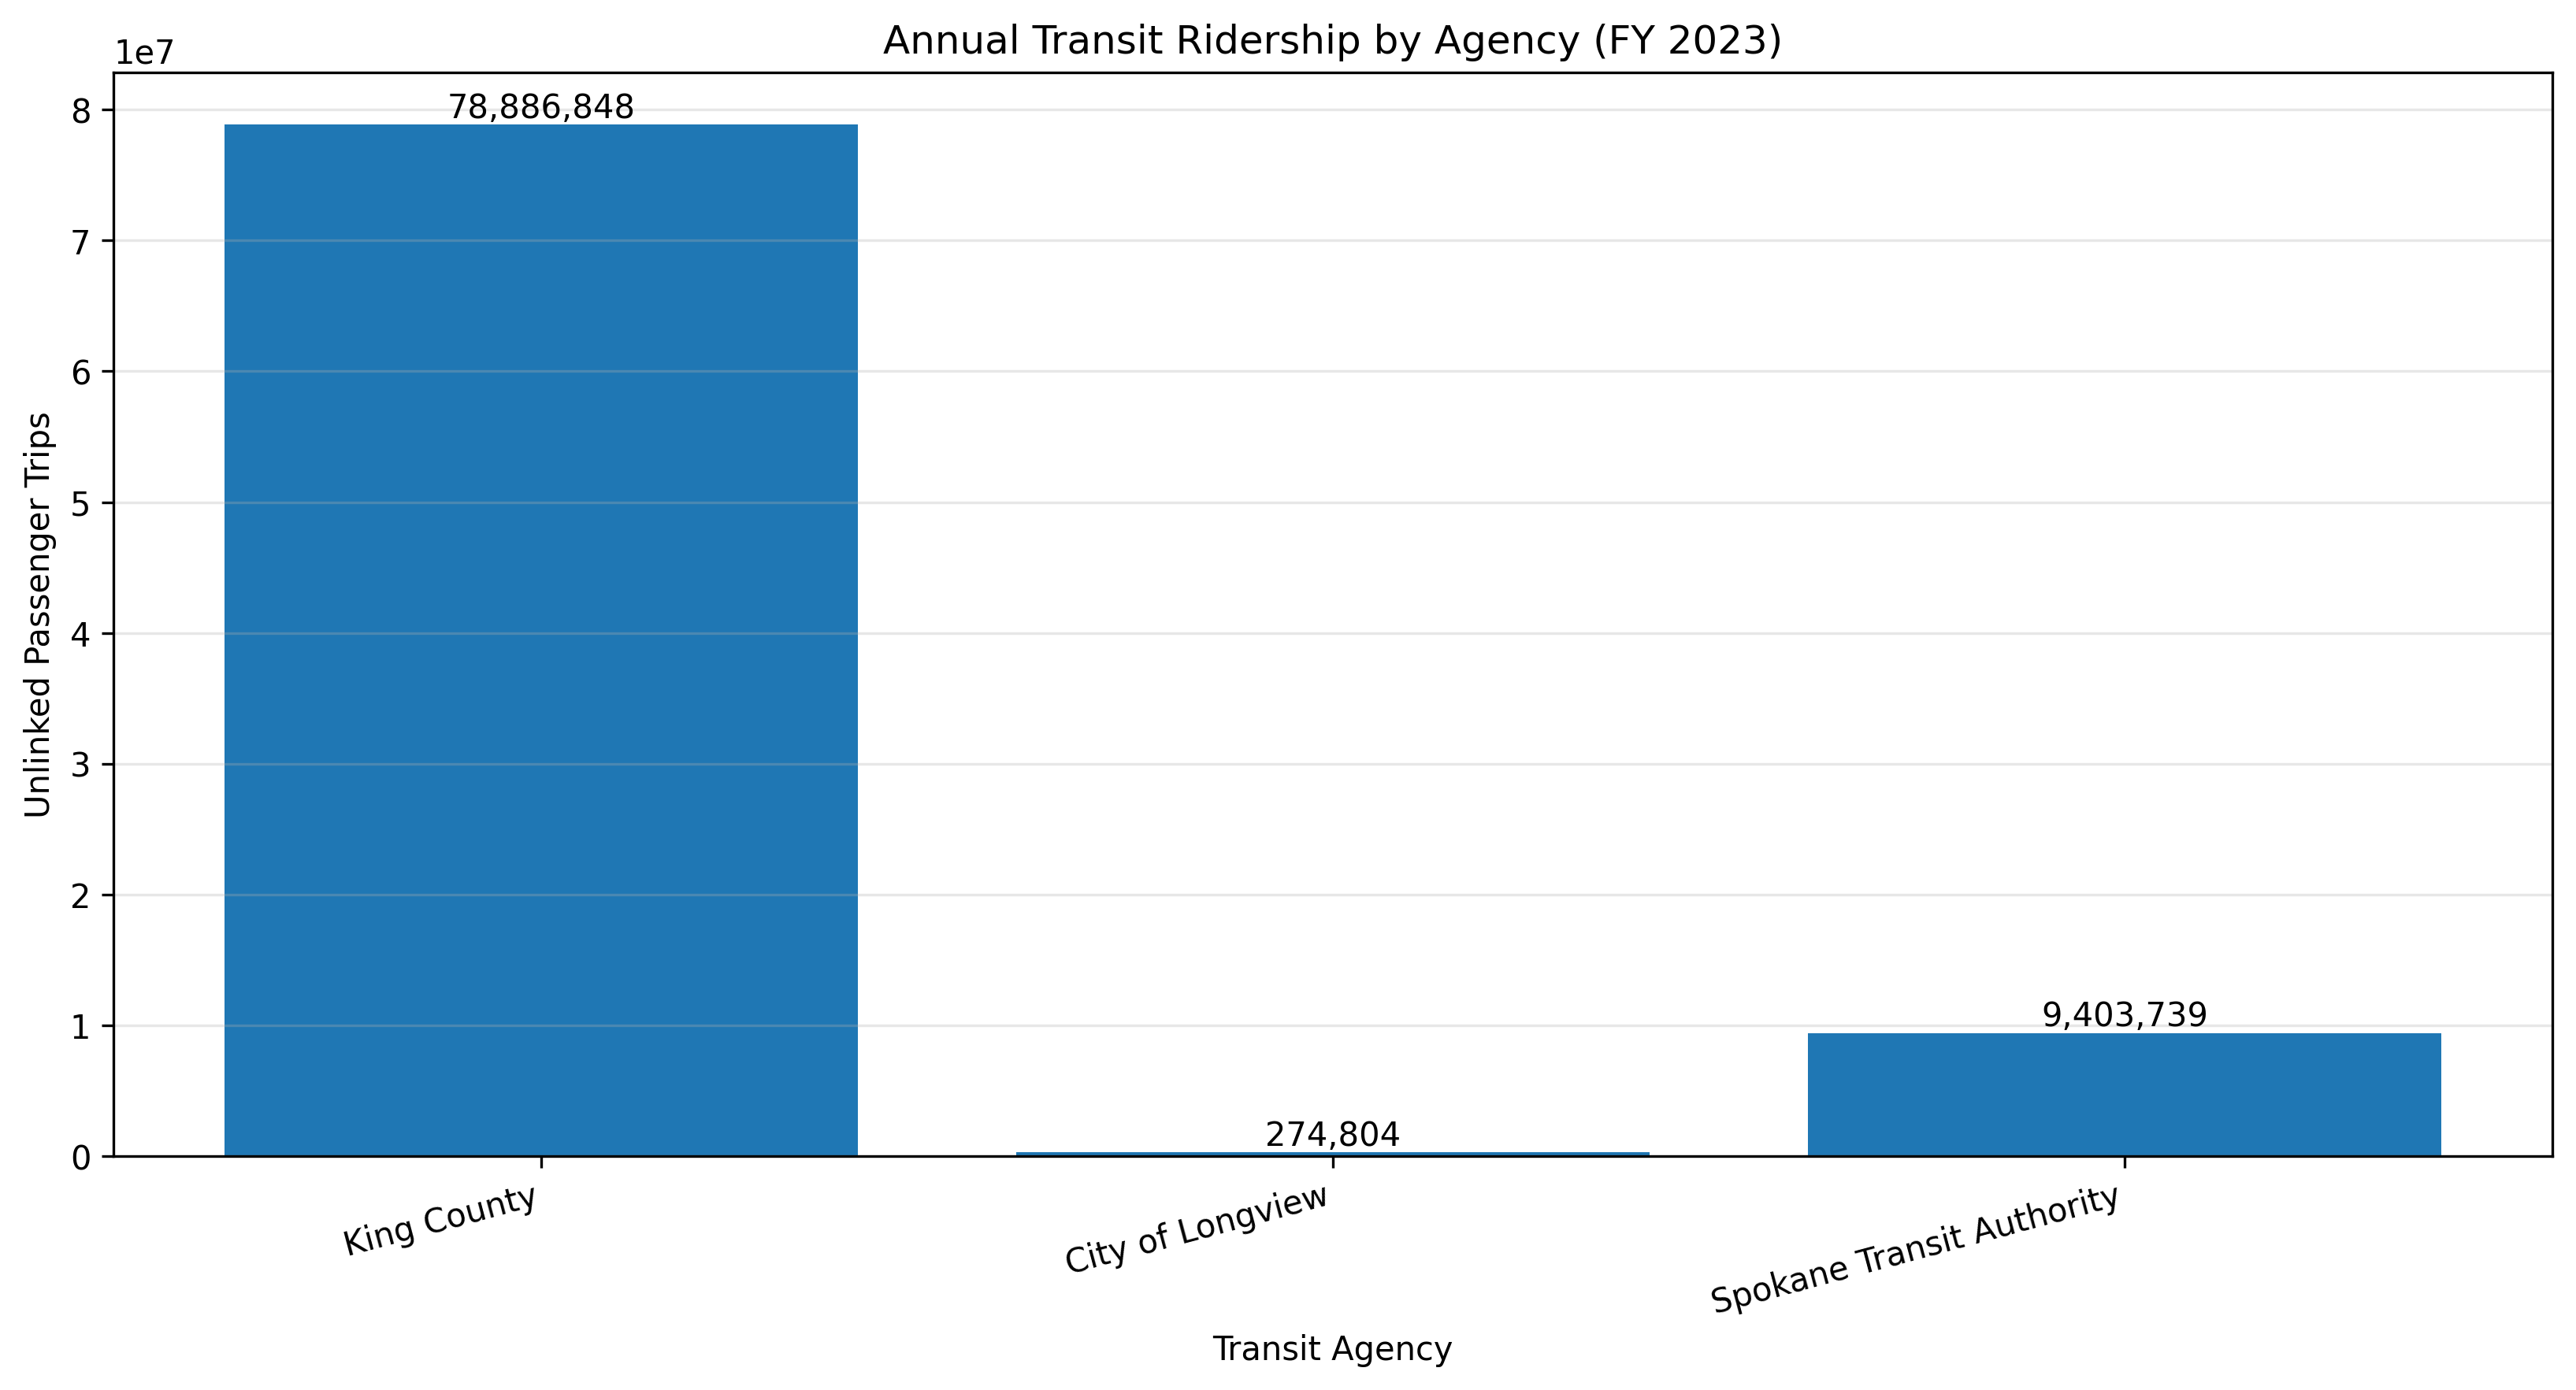

Annual Ridership Summary (FY 2023):
Agency
King County                  78886848
City of Longview               274804
Spokane Transit Authority     9403739


In [9]:
# Visualization 1: Compare annual transit ridership by agency.
# Use the most recent fiscal year to avoid mixing years.
analysis_year = int(filtered_df["Last Closed FY End Year"].max())

recent_df = filtered_df[
    filtered_df["Last Closed FY End Year"] == analysis_year
].copy()

# Calculate total passenger trips for each transit agency.
ridership_by_agency = (
    recent_df.groupby("Agency")["Unlinked Passenger Trips FY"]
    .sum()
    .reindex(neighborhoods)
    .fillna(0)
)

# Create a bar chart comparing ridership.
plt.figure(figsize=(11, 6))
bars = plt.bar(
    ridership_by_agency.index,
    ridership_by_agency.values
)

# Add descriptive labels and a chart title.
plt.title(f"Annual Transit Ridership by Agency (FY {analysis_year})")
plt.xlabel("Transit Agency")
plt.ylabel("Unlinked Passenger Trips")
plt.xticks(rotation=15, ha="right")
plt.grid(axis="y", alpha=0.3)

# Display the passenger trip total above each bar.
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:,.0f}",
        ha="center",
        va="bottom"
    )

# Save the visualization as a PNG file.
plt.tight_layout()
image_path = os.path.join(output_folder, "visualization_1.png")
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.close()

# Display the saved image in the notebook.
display(Image(filename=image_path))

# Print totals for use in the written report.
print(f"Annual Ridership Summary (FY {analysis_year}):")
print(ridership_by_agency.to_string())

### Visualization 2: Bar chart comparing total ridership across neighborhoods
This is an example visualization you can generate. You may implement a chart and assessment of your choosing in lieu of this placeholder.

#### At a minimum include the following actions:
- Add title and axis labels
- Save the plot to a png file in the 'output' folder
- Use the display() function to render the generated png image in the html output
- Comments explaining each step of your analysis

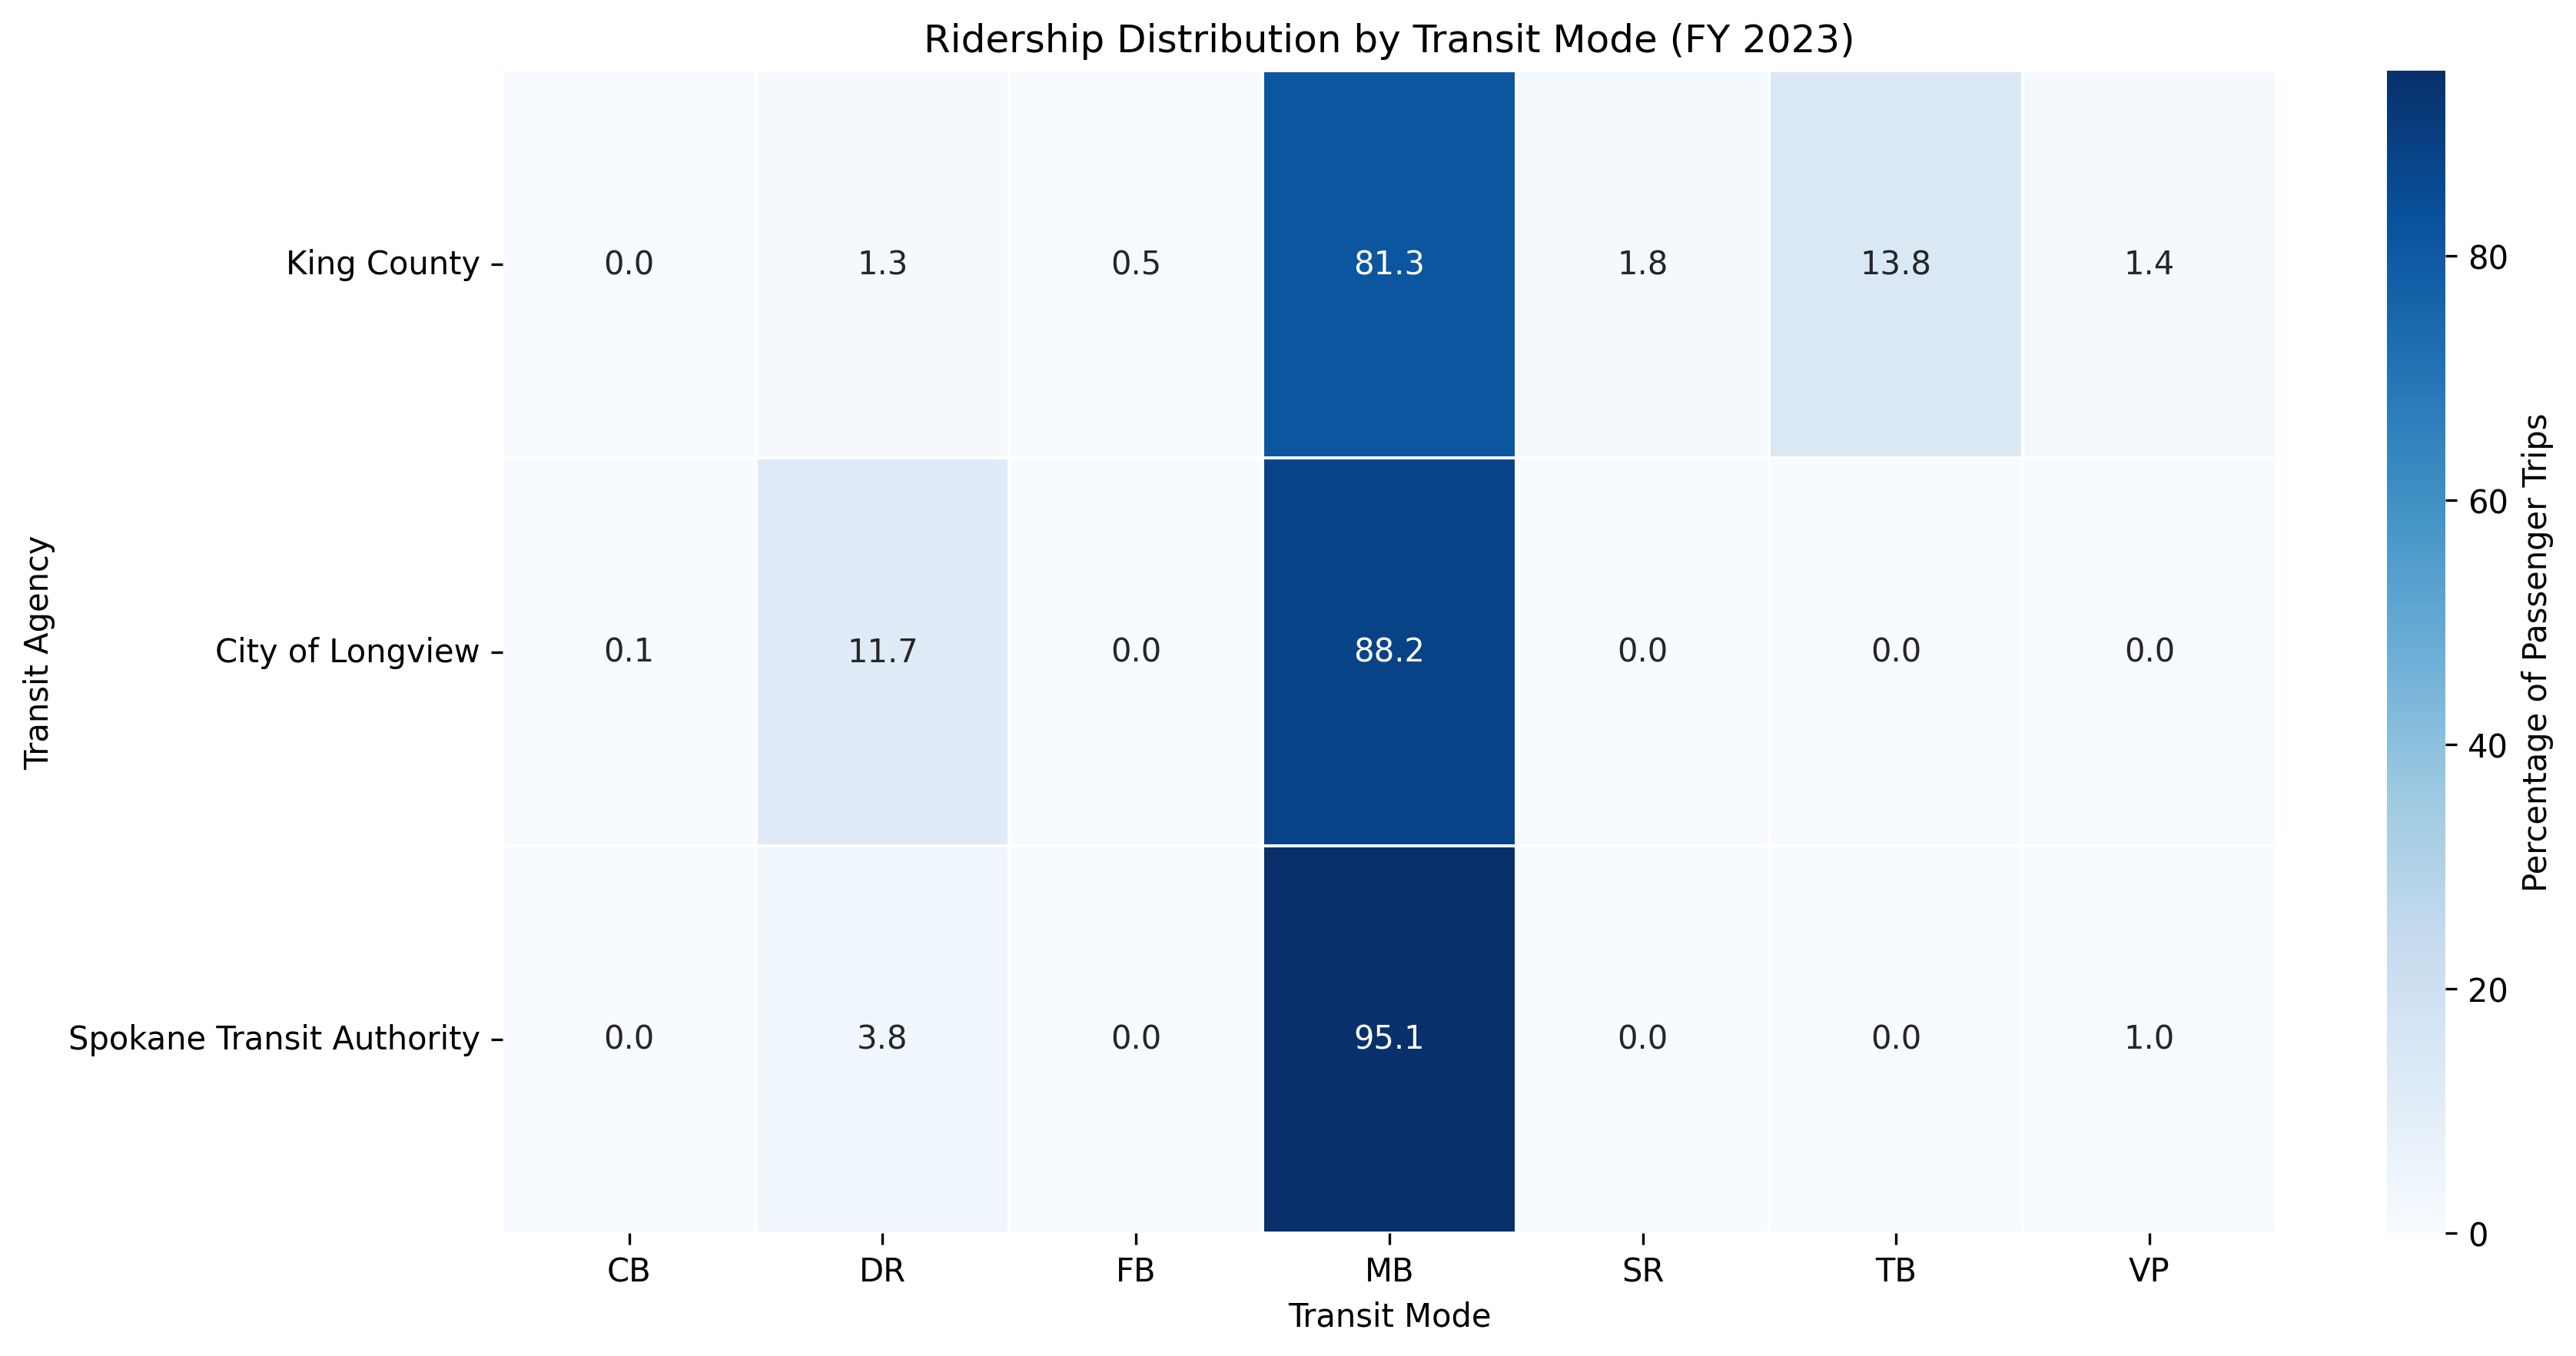

Transit Mode Ridership Percentages:
Mode                         CB     DR    FB     MB    SR     TB    VP
Agency                                                                
King County                0.00   1.28  0.51  81.27  1.79  13.76  1.40
City of Longview           0.11  11.67  0.00  88.22  0.00   0.00  0.00
Spokane Transit Authority  0.00   3.84  0.00  95.14  0.00   0.00  1.02


In [10]:
# Visualization 2: Compare ridership distribution by
# transportation mode across the three transit agencies.

# Group annual passenger trips by agency and transit mode.
mode_ridership = recent_df.groupby(
    ["Agency", "Mode"]
)["Unlinked Passenger Trips FY"].sum().unstack(fill_value=0)

# Arrange the transit agencies in the same order as
# the previous visualization.
mode_ridership = mode_ridership.reindex(
    neighborhoods, fill_value=0
)

# Calculate each mode's percentage of total agency ridership.
mode_percentages = mode_ridership.div(
    mode_ridership.sum(axis=1),
    axis=0
).fillna(0) * 100

# Create a heatmap to identify transportation patterns.
plt.figure(figsize=(12, 6))

sns.heatmap(
    mode_percentages,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Percentage of Passenger Trips"}
)

# Add descriptive chart labels.
plt.title(
    f"Ridership Distribution by Transit Mode (FY {analysis_year})"
)
plt.xlabel("Transit Mode")
plt.ylabel("Transit Agency")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

# Save the completed visualization.
plt.tight_layout()
image_path = os.path.join(
    output_folder, "visualization_2.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.close()

# Display the saved visualization in the notebook.
display(Image(filename=image_path))

# Print the percentages for the written report.
print("Transit Mode Ridership Percentages:")
print(mode_percentages.round(2).to_string())

### Visualization 3: Scatterplot of ridership vs population
This is an example visualization you can generate. You may implement a chart and assessment of your choosing in lieu of this placeholder.

#### At a minimum include the following actions:
- Add title and axis labels
- Save the plot to a png file in the 'output' folder
- Use the display() function to render the generated png image in the html output
- Comments explaining each step of your analysis

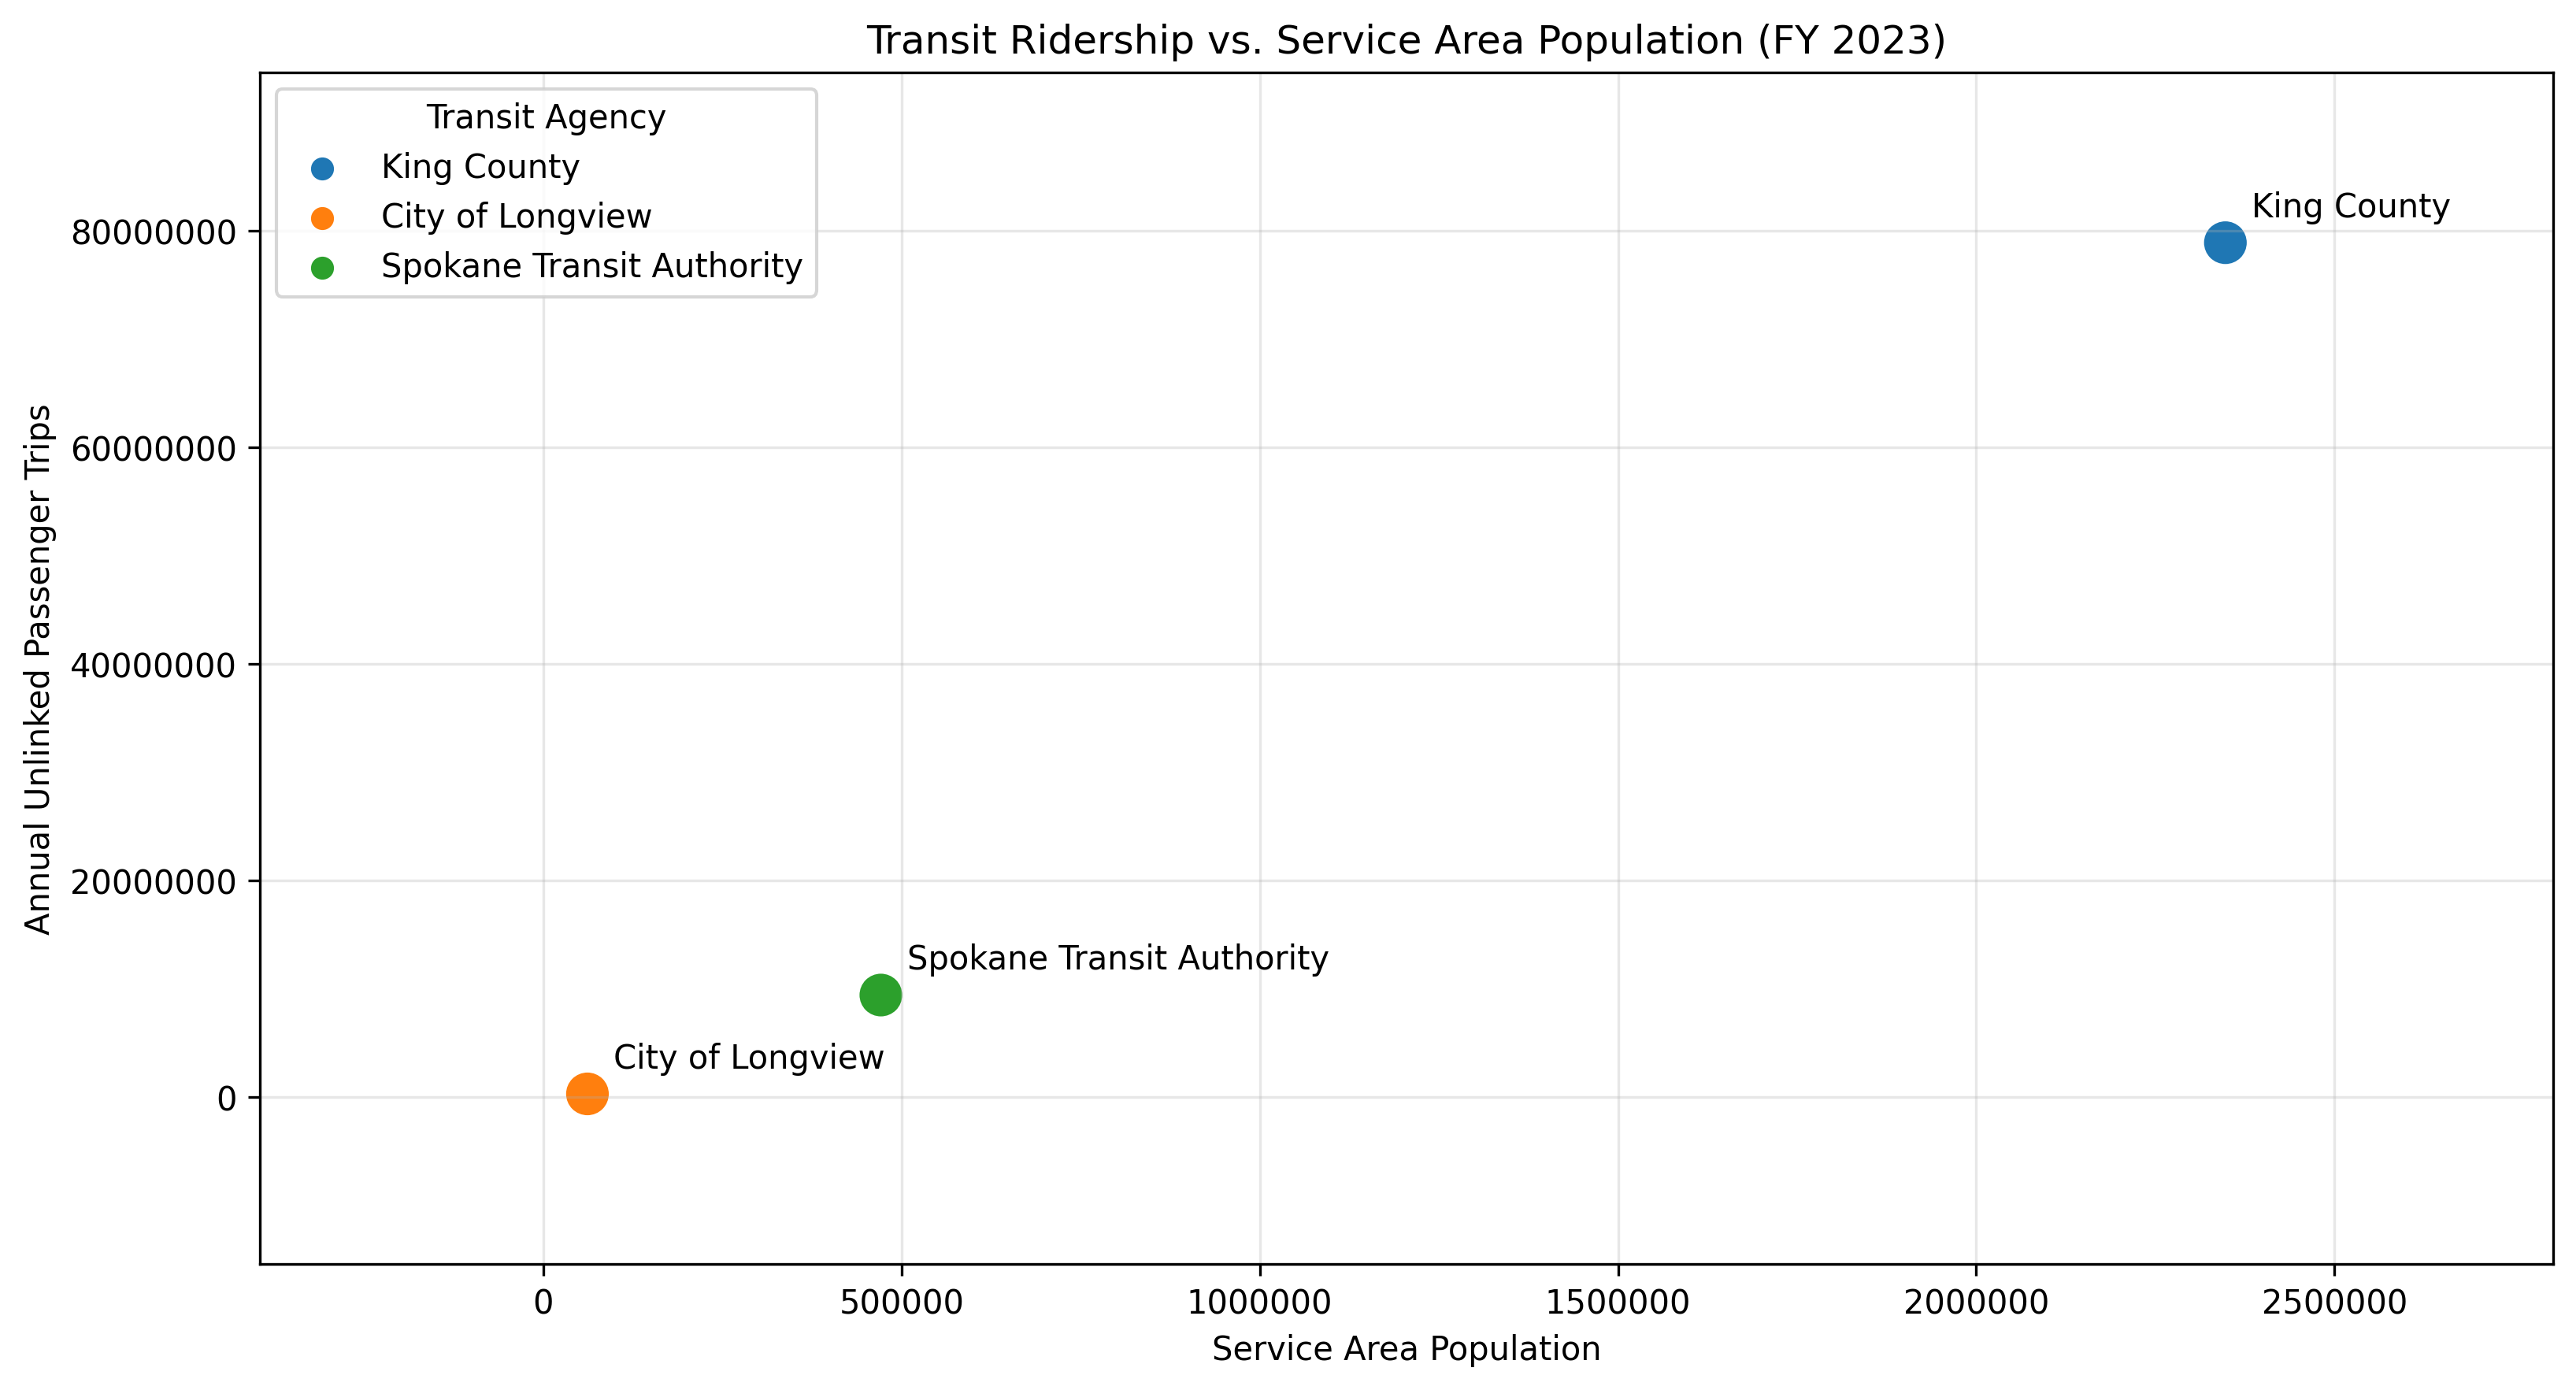

Ridership and Population Comparison:
                   Agency  total_trips  service_population  trips_per_resident
              King County     78886848           2347800.0               33.60
         City of Longview       274804             61598.0                4.46
Spokane Transit Authority      9403739            471169.0               19.96


In [11]:
# Visualization 3: Examine the relationship between
# service area population and annual transit ridership.

# Aggregate total passenger trips for each transit agency.
# Use the largest reported service area population
# rather than adding population across transit modes.
agency_summary = recent_df.groupby("Agency").agg(
    total_trips=("Unlinked Passenger Trips FY", "sum"),
    service_population=("Service Area Population", "max")
).reindex(neighborhoods).reset_index()

# Calculate annual passenger trips per service area resident.
# This represents trip frequency, not unique riders.
agency_summary["trips_per_resident"] = (
    agency_summary["total_trips"] /
    agency_summary["service_population"]
)

# Create a scatterplot comparing population and ridership.
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=agency_summary,
    x="service_population",
    y="total_trips",
    hue="Agency",
    s=200
)

# Label each agency's data point.
for _, row in agency_summary.iterrows():
    plt.annotate(
        row["Agency"],
        (row["service_population"], row["total_trips"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=10
    )

# Add a descriptive title and axis labels.
plt.title(
    f"Transit Ridership vs. Service Area Population (FY {analysis_year})"
)
plt.xlabel("Service Area Population")
plt.ylabel("Annual Unlinked Passenger Trips")

# Improve readability.
plt.ticklabel_format(style="plain", axis="both")
plt.grid(True, alpha=0.3)
plt.margins(x=0.20, y=0.20)
plt.legend(title="Transit Agency")

# Save the scatterplot in the output folder.
plt.tight_layout()
image_path = os.path.join(
    output_folder, "visualization_3.png"
)
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.close()

# Display the saved image in Jupyter Notebook.
display(Image(filename=image_path))

# Print the results for the written report.
print("Ridership and Population Comparison:")
print(agency_summary.round(2).to_string(index=False))